# P2 — EDA del inventario estimado y target de riesgo a una hora

**Objetivo:** explorar un mes de viajes, comparar tres supuestos iniciales (25 %, 50 %, 75 %), probar el **reinicio diario** del inventario y construir `riesgo` para la **siguiente hora (t+1)**.

**Alcance del EDA:** aunque el repositorio detecte **40 archivos mensuales**, este notebook utiliza **únicamente `archivos[0]`**, que con el orden esperado corresponde a **`datos_abiertos_2023_06.parquet` (junio 2023)**. El número real de archivos se imprime al ejecutar. Ningún resultado de aquí debe interpretarse como una evaluación de todos los meses.

**Importante:** el inventario y el target son **aproximaciones (proxy)**, no registros de disponibilidad real de MiBici. Los cálculos y gráficos exploratorios **no entrenan modelos** ni sustituyen la validación completa del pipeline.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "mibici").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from mibici import config

2026-10-18 19:38:19.830 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /Users/MI21861/Documents/MLOPS proyecto/TC5061-Proyecto-Equipo06


Se listan los archivos disponibles, pero **solo se carga el primer Parquet ordenado alfabéticamente**. Para que el análisis sea reproducible, verificamos que sea junio de 2023. También leemos la nomenclatura disponible, cuya capacidad puede no corresponder históricamente a 2023.

In [ ]:
archivos = sorted(config.PROCESSED_DATA_DIR.glob("datos_abiertos_*.parquet"))
print("Meses disponibles:", len(archivos))
if not archivos:
    raise FileNotFoundError("No hay Parquet en data/processed/. Ejecuta antes la ingesta.")
assert archivos[0].name == "datos_abiertos_2023_06.parquet", (
    f"Se esperaba junio 2023 en archivos[0], pero aparece {archivos[0].name}"
)
viajes = pd.read_parquet(archivos[0])
print("Archivo utilizado en TODO este EDA:", archivos[0].name)
print("Viajes:", len(viajes))
display(viajes.head())

catalogos = sorted(config.RAW_DATA_DIR.glob("*nomenclatura*.csv"))
if not catalogos:
    raise FileNotFoundError("No se encontró la nomenclatura en data/raw/")
try:
    estaciones = pd.read_csv(catalogos[-1], encoding="utf-8-sig")
except UnicodeDecodeError:
    estaciones = pd.read_csv(catalogos[-1], encoding="latin-1")
print("Nomenclatura utilizada:", catalogos[-1].name)
display(estaciones.head())

Meses disponibles: 40
Archivo utilizado en TODO este EDA: datos_abiertos_2023_06.parquet
Viajes: 339628


,viaje_id,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
0,28897410,2023-06-01 00:00:40,2023-06-01 00:09:26,20,255
1,28897411,2023-06-01 00:00:46,2023-06-01 00:13:33,20,12
2,28897412,2023-06-01 00:00:55,2023-06-01 00:01:10,273,273
3,28897413,2023-06-01 00:00:59,2023-06-01 00:12:41,273,246
4,28897414,2023-06-01 00:01:20,2023-06-01 00:12:33,273,246


Nomenclatura utilizada: nomenclatura_2026_09.csv


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


In [3]:
v = viajes.copy()
v["inicio_del_viaje"] = pd.to_datetime(v["inicio_del_viaje"], errors="coerce")
v["fin_del_viaje"] = pd.to_datetime(v["fin_del_viaje"], errors="coerce")
for col in ("origen_id", "destino_id"):
    v[col] = pd.to_numeric(v[col], errors="coerce")

est = estaciones.rename(columns={"id": "estacion_id", "dpcapacity": "capacidad"}).copy()
assert {"estacion_id", "capacidad"}.issubset(est.columns)
est["estacion_id"] = pd.to_numeric(est["estacion_id"], errors="coerce")
est["capacidad"] = pd.to_numeric(est["capacidad"], errors="coerce")
# Calidad de la nomenclatura: no inventar capacidades faltantes o iguales a cero.
est = est[["estacion_id", "capacidad"]].copy()
invalidas = est[
    est["estacion_id"].isna()
    | est["capacidad"].isna()
    | (est["capacidad"] <= 0)
].copy()
print(f"Estaciones descartadas por ID o capacidad inválida: {len(invalidas)}")
if not invalidas.empty:
    display(invalidas.head(15))
est = est.dropna(subset=["estacion_id", "capacidad"])
est = est.loc[est["capacidad"] > 0].copy()
assert not est.empty, "No quedan estaciones con capacidad válida"
assert not est["estacion_id"].duplicated().any(), "Estaciones duplicadas en nomenclatura"
print(f"Estaciones válidas en nomenclatura: {len(est)}")

salidas = (v.assign(hora=v["inicio_del_viaje"].dt.floor("h"))
           .groupby(["origen_id", "hora"]).size().rename("salidas")
           .reset_index().rename(columns={"origen_id": "estacion_id"}))
llegadas = (v.assign(hora=v["fin_del_viaje"].dt.floor("h"))
            .groupby(["destino_id", "hora"]).size().rename("llegadas")
            .reset_index().rename(columns={"destino_id": "estacion_id"}))

inicio = pd.Timestamp("2023-06-01 00:00:00")
fin = pd.Timestamp("2023-06-30 23:00:00")
horas = pd.date_range(inicio, fin, freq="h")
ids = pd.Index(pd.concat([salidas["estacion_id"], llegadas["estacion_id"]]).dropna().unique())
ids = ids.intersection(pd.Index(est["estacion_id"]))
malla = pd.MultiIndex.from_product([ids, horas], names=["estacion_id", "hora"]).to_frame(index=False)
malla = (malla.merge(salidas, on=["estacion_id", "hora"], how="left", validate="one_to_one")
         .merge(llegadas, on=["estacion_id", "hora"], how="left", validate="one_to_one")
         .merge(est, on="estacion_id", how="left", validate="many_to_one"))
malla[["salidas", "llegadas"]] = malla[["salidas", "llegadas"]].fillna(0).astype(int)
malla = malla.sort_values(["estacion_id", "hora"]).reset_index(drop=True)
malla["saldo"] = malla["llegadas"] - malla["salidas"]
print("Dimensión de la malla:", malla.shape, "| Estaciones:", malla.estacion_id.nunique())
print("Capacidades faltantes:", malla.capacidad.isna().sum())
display(malla.head())

Estaciones descartadas por ID o capacidad inválida: 4


,estacion_id,capacidad
94,99,0
104,109,0
111,116,0
129,138,0


Estaciones válidas en nomenclatura: 480
Dimensión de la malla: (216000, 6) | Estaciones: 300
Capacidades faltantes: 0


,estacion_id,hora,salidas,llegadas,capacidad,saldo
0,2,2023-06-01 00:00:00,0,0,15,0
1,2,2023-06-01 01:00:00,0,0,15,0
2,2,2023-06-01 02:00:00,0,0,15,0
3,2,2023-06-01 03:00:00,0,0,15,0
4,2,2023-06-01 04:00:00,0,0,15,0


,salidas,llegadas,saldo,capacidad
count,216000.000000,216000.000000,216000.000000,216000.000000
mean,1.572352,1.572227,-0.000125,16.690000
std,2.660933,2.761929,2.089663,4.378811
min,0.000000,0.000000,-71.000000,11.000000
25%,0.000000,0.000000,-1.000000,15.000000
50%,1.000000,1.000000,0.000000,15.000000
75%,2.000000,2.000000,0.000000,19.000000
max,80.000000,97.000000,71.000000,39.000000


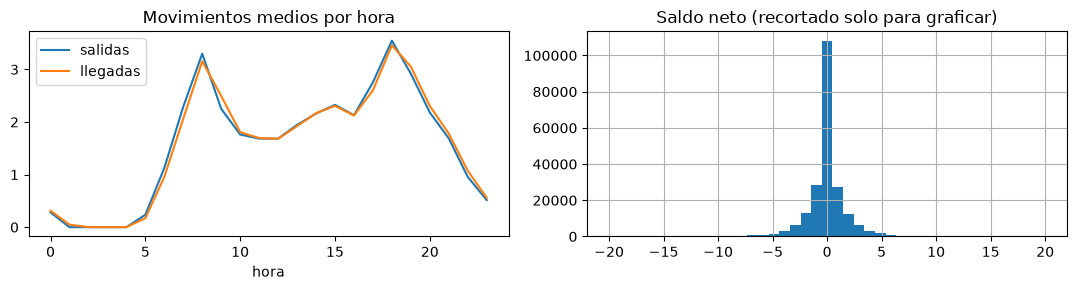

In [4]:
display(malla[["salidas", "llegadas", "saldo", "capacidad"]].describe())
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
malla.groupby(malla["hora"].dt.hour)[["salidas", "llegadas"]].mean().plot(ax=axes[0], title="Movimientos medios por hora")
malla["saldo"].clip(-20, 20).hist(bins=41, ax=axes[1])
axes[1].set_title("Saldo neto (recortado solo para graficar)")
plt.tight_layout(); plt.show()


Probamos inventarios iniciales de **25 %, 50 % y 75 %** de la capacidad. Cada día y estación empiezan con el porcentaje elegido, **antes** de aplicar las llegadas y salidas de la primera hora de ese día. Los movimientos de cada hora actualizan el inventario, que se recorta al intervalo `[0, capacidad]`.

No sabemos si esos valores corresponden a la ocupación real; el reinicio limita acumulación de errores, pero no los elimina.

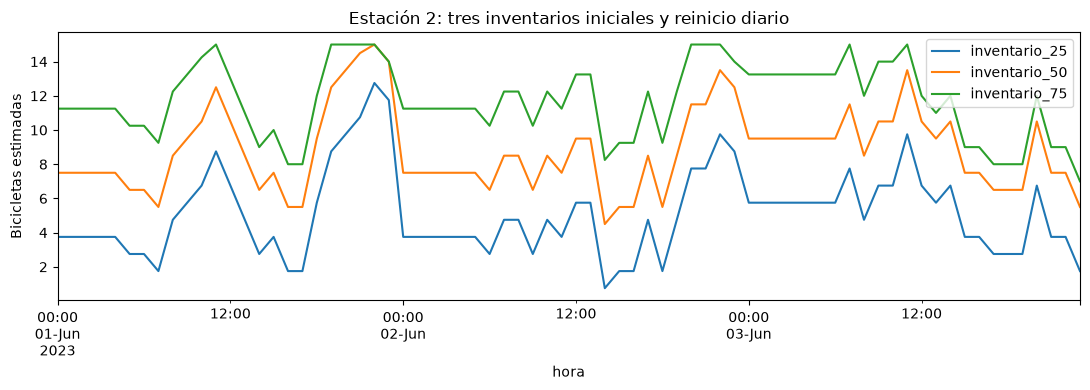

In [5]:
def inventario_exploratorio_diario(malla, porcentaje_inicial):
    """Simulación exploratoria: reinicio diario por estación; no modifica features.py."""
    if not 0 <= porcentaje_inicial <= 1:
        raise ValueError("El porcentaje debe estar entre 0 y 1")
    orden = malla.sort_values(["estacion_id", "hora"]).copy()
    sal = orden["salidas"].to_numpy(dtype=float)
    lle = orden["llegadas"].to_numpy(dtype=float)
    cap = orden["capacidad"].to_numpy(dtype=float)
    inv = np.empty(len(orden), dtype=float)
    fecha = orden["hora"].dt.normalize()
    for posiciones in orden.groupby(["estacion_id", fecha], sort=False).indices.values():
        saldo = cap[posiciones[0]] * porcentaje_inicial
        for p in posiciones:
            saldo = min(cap[p], max(0.0, saldo + lle[p] - sal[p]))
            inv[p] = saldo
    return pd.Series(inv, index=orden.index).reindex(malla.index)

for pct in (25, 50, 75):
    malla[f"inventario_{pct}"] = inventario_exploratorio_diario(malla, pct / 100)

ejemplo_id = malla["estacion_id"].iloc[0]
ejemplo = malla[malla["estacion_id"] == ejemplo_id].head(72)
ejemplo.plot(x="hora", y=["inventario_25", "inventario_50", "inventario_75"],
             figsize=(11, 4), title=f"Estación {ejemplo_id}: tres inventarios iniciales y reinicio diario")
plt.ylabel("Bicicletas estimadas"); plt.tight_layout(); plt.show()

Construir etiquetas exploratorias a **una hora**

`riesgo = 1` si el inventario estimado **al final de la hora siguiente** es ≤10 % o ≥90 % de capacidad. `riesgo = 0` en los demás casos con hora futura válida. Las filas de las **23:00** y las que carezcan de hora consecutiva quedan en `NA` porque cruzan un reinicio diario o carecen de futuro.

In [6]:
siguiente_hora = malla.groupby("estacion_id")["hora"].shift(-1)
valido = ((siguiente_hora - malla["hora"] == pd.Timedelta(hours=1)) &
          (siguiente_hora.dt.normalize() == malla["hora"].dt.normalize()))
for pct in (25, 50, 75):
    futuro = malla.groupby("estacion_id")[f"inventario_{pct}"].shift(-1)
    critico = ((futuro <= 0.10 * malla["capacidad"]) |
               (futuro >= 0.90 * malla["capacidad"]))
    malla[f"riesgo_{pct}"] = critico.astype("Int64").where(valido, pd.NA)
    validos = malla[f"riesgo_{pct}"].dropna()
    print(f"Inventario inicial {pct}%: riesgo={validos.mean():.1%}; N={len(validos):,}; NA={malla[f'riesgo_{pct}'].isna().sum():,}")

Inventario inicial 25%: riesgo=24.2%; N=207,000; NA=9,000
Inventario inicial 50%: riesgo=15.4%; N=207,000; NA=9,000
Inventario inicial 75%: riesgo=18.5%; N=207,000; NA=9,000


/var/folders/tl/jxdd9c6s3vz8qc0997t580dw0000gp/T/ipykernel_10429/2863704904.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  valido = ((siguiente_hora - malla["hora"] == pd.Timedelta(hours=1)) &


,inventario_inicial,vacio_%,lleno_%,extremos_%
0,25%,11.31,2.08,13.40
1,50%,4.30,3.95,8.25
2,75%,2.17,8.56,10.73


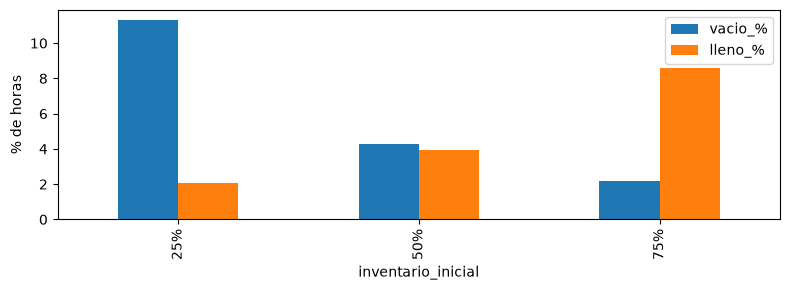

In [7]:
saturacion = pd.DataFrame([{
    "inventario_inicial": f"{pct}%",
    "vacio_%": 100 * (malla[f"inventario_{pct}"] == 0).mean(),
    "lleno_%": 100 * (malla[f"inventario_{pct}"] == malla["capacidad"]).mean(),
    "extremos_%": 100 * ((malla[f"inventario_{pct}"] == 0) |
                           (malla[f"inventario_{pct}"] == malla["capacidad"])).mean(),
} for pct in (25, 50, 75)])
display(saturacion.round(2))
saturacion.set_index("inventario_inicial")[["vacio_%", "lleno_%"]].plot.bar(figsize=(8, 3))
plt.ylabel("% de horas"); plt.tight_layout(); plt.show()

,riesgo_25,riesgo_50,riesgo_75
fecha,,,
2023-06-01,28.3,19.4,20.2
2023-06-02,26.3,16.8,19.9
2023-06-03,21.0,10.8,14.9
2023-06-04,16.1,7.4,13.3
2023-06-05,27.2,18.6,20.4
2023-06-06,26.7,18.1,20.0
2023-06-07,27.4,19.0,20.9
2023-06-08,28.2,17.9,19.7
2023-06-09,26.0,17.2,19.4


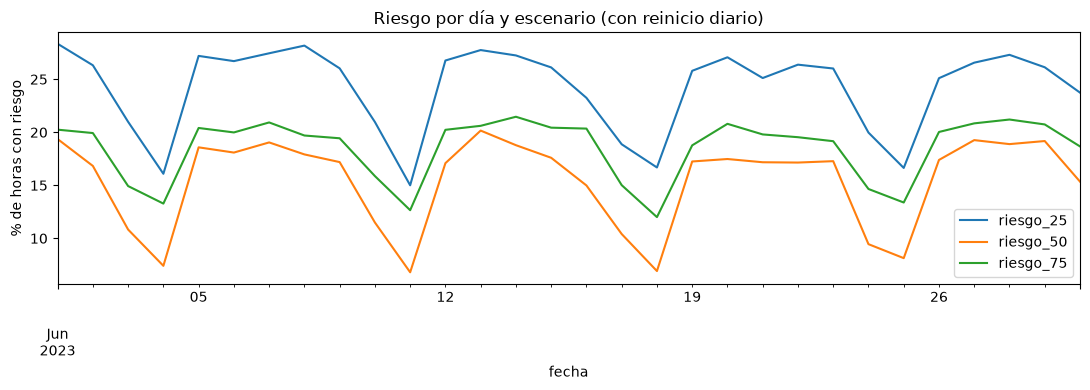

In [8]:
riesgo_diario = (malla.assign(fecha=malla["hora"].dt.normalize())
                 .groupby("fecha")[["riesgo_25", "riesgo_50", "riesgo_75"]].mean() * 100)
display(riesgo_diario.round(1))
riesgo_diario.plot(figsize=(11, 4), title="Riesgo por día y escenario (con reinicio diario)")
plt.ylabel("% de horas con riesgo"); plt.tight_layout(); plt.show()

In [9]:
comparaciones = []
for a, b in ((25, 50), (25, 75), (50, 75)):
    x, y = malla[f"riesgo_{a}"], malla[f"riesgo_{b}"]
    mask = x.notna() & y.notna()
    comparaciones.append({"escenarios": f"{a}% y {b}%",
                          "horas_comparadas": int(mask.sum()),
                          "coincidencia_%": 100 * (x[mask] == y[mask]).mean()})
display(pd.DataFrame(comparaciones).round(2))

,escenarios,horas_comparadas,coincidencia_%
0,25% y 50%,207000,84.47
1,25% y 75%,207000,71.87
2,50% y 75%,207000,87.40


## Interpretación y limitaciones

- **Alcance:** el EDA emplea **solo junio de 2023** (`archivos[0]`), aunque se detecten 40 meses. No se extrapolan estos resultados al periodo completo.
- **Exploratorio:** la malla creada aquí, las simulaciones con 25/50/75 %, las gráficas, la saturación y las comparaciones sirven para **evaluar supuestos**, no son métricas de calidad predictiva ni entrenamiento del clasificador.
- **Decisión para P2:** la función candidata reinicia al 50 % al inicio de cada día y etiqueta como riesgo los extremos ≤10 % o ≥90 % **en la siguiente hora**.
- **NA:** al final de cada día o cuando falta una hora consecutiva, el riesgo es desconocido bajo este esquema y no debe tratarse como 0. Estas filas se excluyen al entrenar.
- **Limitación:** no hay inventario real ni registros de rebalanceo; reiniciar reduce la acumulación del error, pero no valida la estimación. La nomenclatura elegida puede diferir de la capacidad de 2023.

**Antes de documentar porcentajes o conclusiones numéricas, ejecutar todas las celdas y revisar sus resultados.**